## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64


np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## 3 hidden layers of 50 neurons, each a linear layer followed by a ReLU, then a linear output layer with 10 logits
class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307) / 0.3081

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 50)
        self.fc2 = nn.Linear(50, 50)
        self.fc3 = nn.Linear(50, 50)
        self.fc4 = nn.Linear(50, 10)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        return self.fc4(x)   # logits, no softmax

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
def make_model():
    return nn.Sequential(Normalize(), Net()).to(device)

In [2]:
# Affine layer
def affine_bounds(l, u, W, b):
    W_pos = W.clamp(min=0)
    W_neg = W.clamp(max=0)
    new_l = l @ W_pos.T + u @ W_neg.T + b
    new_u = u @ W_pos.T + l @ W_neg.T + b
    return new_l, new_u

# HW2
def relu_bounds(l, u):
    return torch.relu(l), torch.relu(u)

In [3]:
def margin_lower_bounds(model, x, y, eps):
    # HW2
    net = model[1]
    l = torch.clamp(x - eps, 0, 1).view(-1, 28 * 28)
    u = torch.clamp(x + eps, 0, 1).view(-1, 28 * 28)
    l, u = model[0](l), model[0](u)          # Normalize

    for layer in [net.fc1, net.fc2, net.fc3]:
        l, u = affine_bounds(l, u, layer.weight, layer.bias)
        l, u = relu_bounds(l, u)

    # HW2
    W2, b2 = net.fc4.weight, net.fc4.bias
    margins = []
    for j in range(10):
        W = W2[y] - W2[j]
        b = b2[y] - b2[j]
        lower = (W.clamp(min=0) * l + W.clamp(max=0) * u).sum(dim=1) + b
        margins.append(lower)
    return torch.stack(margins, dim=1)

def worst_case_logits(model, x, y, eps):
    return -margin_lower_bounds(model, x, y, eps)

def verified(model, x, y, eps):
    # HW2 criteria: all lower bounds of z_y - z_j are >= 0
    with torch.no_grad():
        return margin_lower_bounds(model, x, y, eps).min(dim=1).values >= 0

In [4]:
check_model = make_model()
x, y = next(iter(test_loader))
x, y = x.to(device), y.to(device)

with torch.no_grad():
    lower = margin_lower_bounds(check_model, x, y, 0.1)
    for _ in range(100):
        # a random image inside the box [x - 0.1, x + 0.1], clipped to [0, 1]
        x_rand = torch.clamp(x + torch.empty_like(x).uniform_(-0.1, 0.1), 0, 1)
        z = check_model(x_rand)
        true_margins = z.gather(1, y.unsqueeze(1)) - z      # z_y - z_j for every class j
        assert (true_margins >= lower - 1e-5).all()
print("bounds are sound")

bounds are sound


In [5]:
EPS_TRAIN = 0.1
EPOCHS = 20
WARMUP_EPOCHS = 1
RAMP_EPOCHS = 10

def ramp(step, warmup_steps, ramp_steps):
    return min(max((step - warmup_steps) / ramp_steps, 0.0), 1.0)

def ibp_loss(model, x, y, eps, omega):
    fit_loss = F.cross_entropy(model(x), y)
    spec_loss = F.cross_entropy(worst_case_logits(model, x, y, eps), y)
    return omega * fit_loss + (1 - omega) * spec_loss

def train(model, certified):
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    warmup_steps = WARMUP_EPOCHS * len(train_loader)
    ramp_steps = RAMP_EPOCHS * len(train_loader)
    step = 0
    start = time.time()
    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if certified:
                t = ramp(step, warmup_steps, ramp_steps)
                eps, omega = EPS_TRAIN * t, 1 - 0.5 * t
                loss = ibp_loss(model, x, y, eps, omega)
            else:
                loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            step += 1
        avg_loss = round(running_loss / len(train_loader), 3)
        if certified:
            print("Epoch", epoch + 1, "/", EPOCHS, "loss:", avg_loss,
                  "eps_train:", round(eps, 3), "omega:", round(omega, 2))
        else:
            print("Epoch", epoch + 1, "/", EPOCHS, "loss:", avg_loss)
    return time.time() - start

In [6]:
#HW1
def pgd_linf_untargeted(model, x, labels, k, eps, eps_step):
    model.eval()
    ce_loss = torch.nn.CrossEntropyLoss()
    # random start 
    adv_x = torch.clamp(x + torch.empty_like(x).uniform_(-eps, eps), 0, 1).detach()
    for _ in range(k):
        adv_x.requires_grad_(True)
        model.zero_grad()
        output = model(adv_x)
        loss = ce_loss(output, labels)
        loss.backward()
        gradient = adv_x.grad.data
        adv_x = adv_x + eps_step * torch.sign(gradient)
        delta = adv_x - x
        delta = torch.clamp(delta, -eps, eps)
        adv_x = torch.clamp(x + delta, 0, 1).detach()
    return adv_x

def evaluate(model, eps):
    model.eval()
    torch.manual_seed(0)   # same PGD random start every time
    clean = 0
    pgd = 0
    cert = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        x_adv = pgd_linf_untargeted(model, x, y, k=10, eps=eps, eps_step=eps / 4)
        with torch.no_grad():
            clean += (model(x).argmax(1) == y).sum().item()
            pgd += (model(x_adv).argmax(1) == y).sum().item()
        cert += verified(model, x, y, eps).sum().item()
    n = len(test_dataset)
    return 100 * clean / n, 100 * pgd / n, 100 * cert / n

In [7]:
torch.manual_seed(0)
std_model = make_model()
std_time = train(std_model, certified=False)
print("Standard training time:", round(std_time, 1), "s")

Epoch 1 / 20 loss: 0.347
Epoch 2 / 20 loss: 0.148
Epoch 3 / 20 loss: 0.11
Epoch 4 / 20 loss: 0.091
Epoch 5 / 20 loss: 0.075
Epoch 6 / 20 loss: 0.065
Epoch 7 / 20 loss: 0.057
Epoch 8 / 20 loss: 0.051
Epoch 9 / 20 loss: 0.046
Epoch 10 / 20 loss: 0.042
Epoch 11 / 20 loss: 0.038
Epoch 12 / 20 loss: 0.035
Epoch 13 / 20 loss: 0.032
Epoch 14 / 20 loss: 0.029
Epoch 15 / 20 loss: 0.027
Epoch 16 / 20 loss: 0.027
Epoch 17 / 20 loss: 0.023
Epoch 18 / 20 loss: 0.022
Epoch 19 / 20 loss: 0.023
Epoch 20 / 20 loss: 0.022
Standard training time: 171.3 s


In [8]:
torch.manual_seed(0)
ibp_model = make_model()
ibp_time = train(ibp_model, certified=True)
print("IBP training time:", round(ibp_time, 1), "s")

Epoch 1 / 20 loss: 0.347 eps_train: 0.0 omega: 1.0
Epoch 2 / 20 loss: 0.198 eps_train: 0.01 omega: 0.95
Epoch 3 / 20 loss: 0.219 eps_train: 0.02 omega: 0.9
Epoch 4 / 20 loss: 0.225 eps_train: 0.03 omega: 0.85
Epoch 5 / 20 loss: 0.243 eps_train: 0.04 omega: 0.8
Epoch 6 / 20 loss: 0.27 eps_train: 0.05 omega: 0.75
Epoch 7 / 20 loss: 0.305 eps_train: 0.06 omega: 0.7
Epoch 8 / 20 loss: 0.348 eps_train: 0.07 omega: 0.65
Epoch 9 / 20 loss: 0.403 eps_train: 0.08 omega: 0.6
Epoch 10 / 20 loss: 0.47 eps_train: 0.09 omega: 0.55
Epoch 11 / 20 loss: 0.542 eps_train: 0.1 omega: 0.5
Epoch 12 / 20 loss: 0.565 eps_train: 0.1 omega: 0.5
Epoch 13 / 20 loss: 0.543 eps_train: 0.1 omega: 0.5
Epoch 14 / 20 loss: 0.529 eps_train: 0.1 omega: 0.5
Epoch 15 / 20 loss: 0.519 eps_train: 0.1 omega: 0.5
Epoch 16 / 20 loss: 0.51 eps_train: 0.1 omega: 0.5
Epoch 17 / 20 loss: 0.502 eps_train: 0.1 omega: 0.5
Epoch 18 / 20 loss: 0.497 eps_train: 0.1 omega: 0.5
Epoch 19 / 20 loss: 0.491 eps_train: 0.1 omega: 0.5
Epoch 20 /

In [9]:
clean, pgd, cert = evaluate(std_model, EPS_TRAIN)
print("standard")
print("clean accuracy:", round(clean, 2))
print("PGD accuracy (eps=0.1):", round(pgd, 2))
print("training time (s):", round(std_time, 1))
print("time per epoch (s):", round(std_time / EPOCHS, 2))

clean, pgd, cert = evaluate(ibp_model, EPS_TRAIN)
print("IBP")
print("clean accuracy:", round(clean, 2))
print("PGD accuracy (eps=0.1):", round(pgd, 2))
print("training time (s):", round(ibp_time, 1))
print("time per epoch (s):", round(ibp_time / EPOCHS, 2))

print("IBP / standard training time:", round(ibp_time / std_time, 2))

standard
clean accuracy: 97.34
PGD accuracy (eps=0.1): 11.54
training time (s): 171.3
time per epoch (s): 8.56
IBP
clean accuracy: 94.42
PGD accuracy (eps=0.1): 86.2
training time (s): 280.1
time per epoch (s): 14.0
IBP / standard training time: 1.64


In [10]:
eps_list = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]

std_verified = []
std_pgd = []
print("standard")
for eps in eps_list:
    clean, pgd, cert = evaluate(std_model, eps)
    std_verified.append(cert)
    std_pgd.append(pgd)
    print("eps:", eps, "verified:", round(cert, 2), "PGD:", round(pgd, 2),
          "attacked:", round(100 - pgd, 2), "unknown:", round(pgd - cert, 2))

ibp_verified = []
ibp_pgd = []
print("IBP")
for eps in eps_list:
    clean, pgd, cert = evaluate(ibp_model, eps)
    ibp_verified.append(cert)
    ibp_pgd.append(pgd)
    print("eps:", eps, "verified:", round(cert, 2), "PGD:", round(pgd, 2),
          "attacked:", round(100 - pgd, 2), "unknown:", round(pgd - cert, 2))

standard
eps: 0.01 verified: 0.0 PGD: 94.8 attacked: 5.2 unknown: 94.8
eps: 0.02 verified: 0.0 PGD: 90.27 attacked: 9.73 unknown: 90.27
eps: 0.03 verified: 0.0 PGD: 82.98 attacked: 17.02 unknown: 82.98
eps: 0.04 verified: 0.0 PGD: 71.37 attacked: 28.63 unknown: 71.37
eps: 0.05 verified: 0.0 PGD: 57.12 attacked: 42.88 unknown: 57.12
eps: 0.06 verified: 0.0 PGD: 42.43 attacked: 57.57 unknown: 42.43
eps: 0.07 verified: 0.0 PGD: 30.67 attacked: 69.33 unknown: 30.67
eps: 0.08 verified: 0.0 PGD: 22.37 attacked: 77.63 unknown: 22.37
eps: 0.09 verified: 0.0 PGD: 16.02 attacked: 83.98 unknown: 16.02
eps: 0.1 verified: 0.0 PGD: 11.54 attacked: 88.46 unknown: 11.54
IBP
eps: 0.01 verified: 93.62 PGD: 93.71 attacked: 6.29 unknown: 0.09
eps: 0.02 verified: 92.89 PGD: 93.19 attacked: 6.81 unknown: 0.3
eps: 0.03 verified: 91.92 PGD: 92.44 attacked: 7.56 unknown: 0.52
eps: 0.04 verified: 90.84 PGD: 91.74 attacked: 8.26 unknown: 0.9
eps: 0.05 verified: 89.63 PGD: 90.87 attacked: 9.13 unknown: 1.24
eps: 

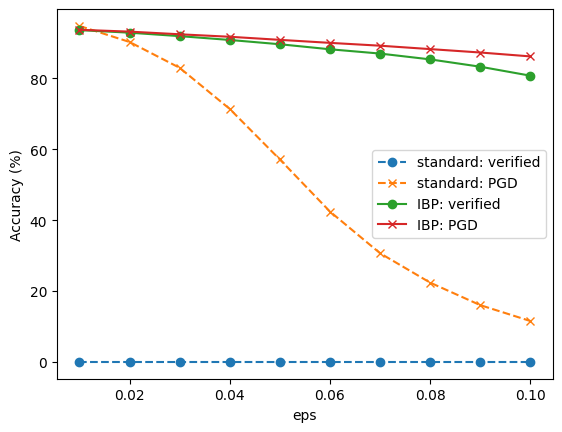

In [11]:
plt.plot(eps_list, std_verified, "--", marker="o", label="standard: verified")
plt.plot(eps_list, std_pgd, "--", marker="x", label="standard: PGD")
plt.plot(eps_list, ibp_verified, "-", marker="o", label="IBP: verified")
plt.plot(eps_list, ibp_pgd, "-", marker="x", label="IBP: PGD")
plt.xlabel("eps")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

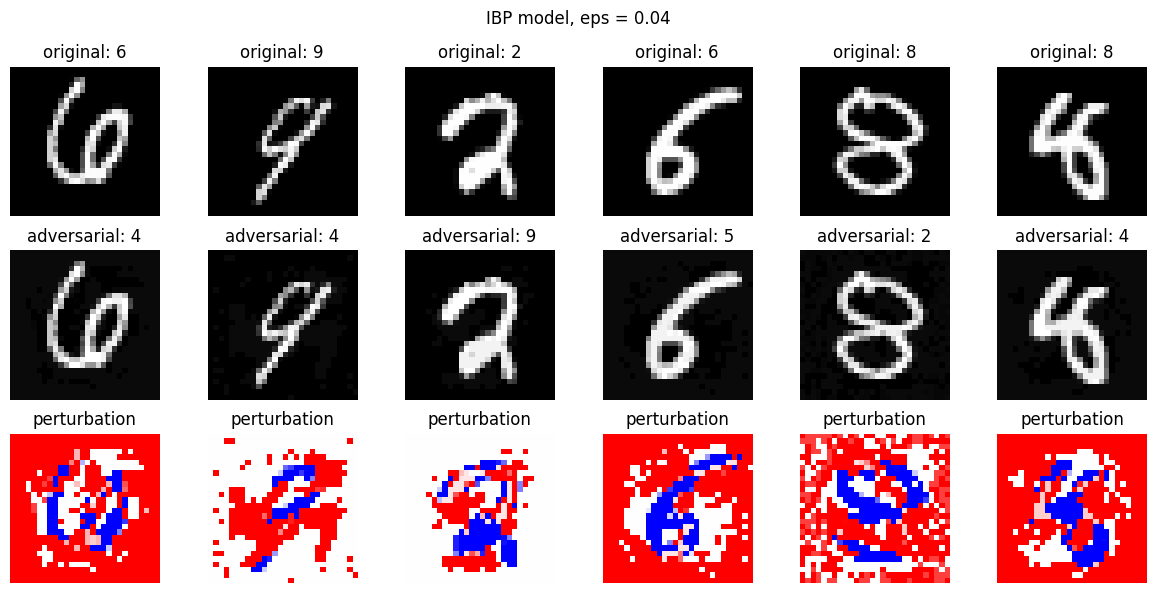

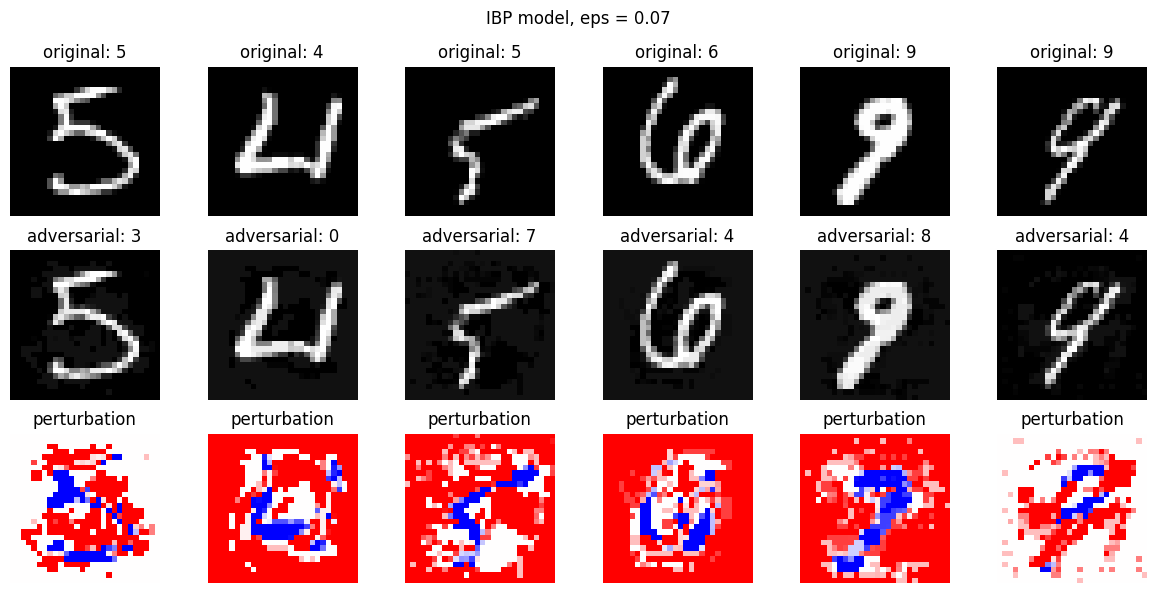

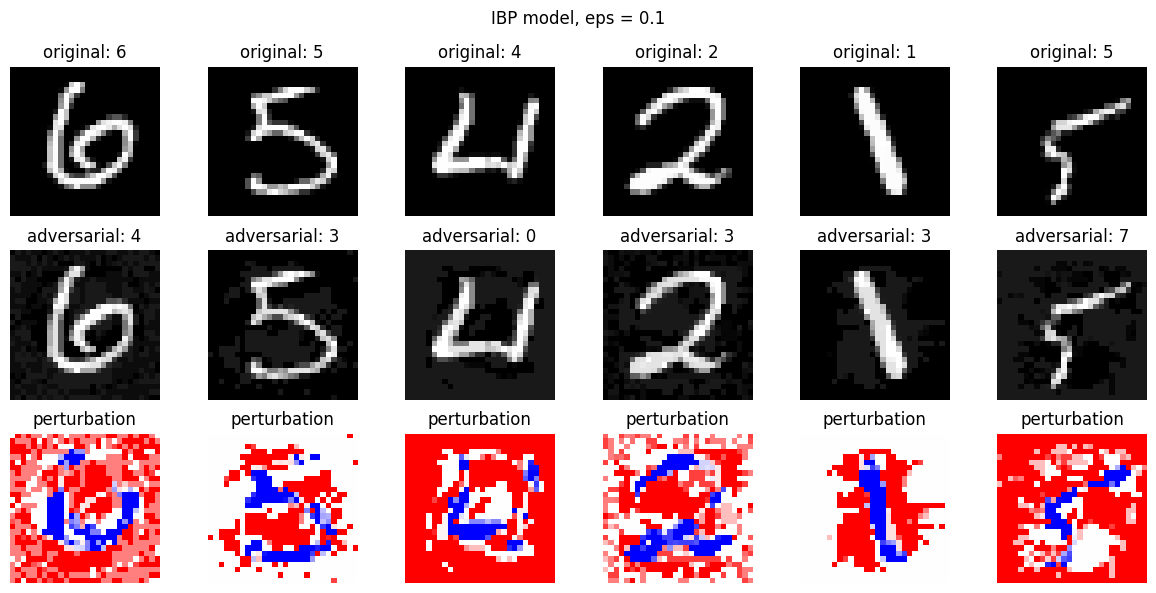

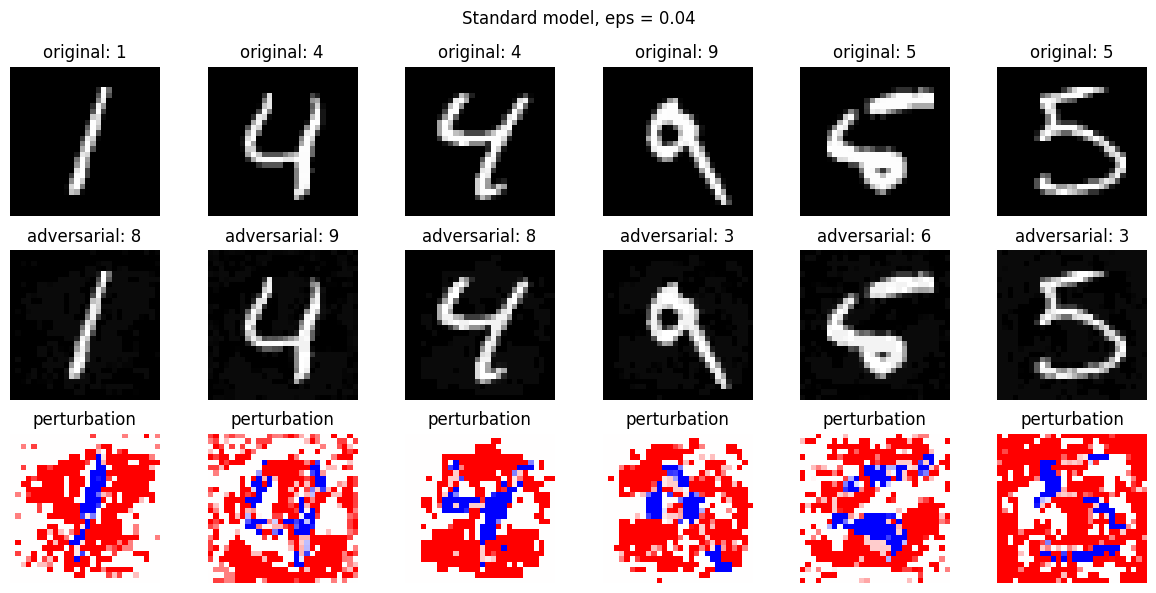

In [12]:
def find_adversarial_examples(model, eps, max_examples=6):
    found = []
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        not_verified = verified(model, x, y, eps) == False
        x_adv = pgd_linf_untargeted(model, x, y, k=10, eps=eps, eps_step=eps / 4)
        with torch.no_grad():
            correct = model(x).argmax(1) == y
            adv_pred = model(x_adv).argmax(1)
        # correct on the clean image, not verified, and PGD changes the prediction
        idx = (not_verified & correct & (adv_pred != y)).nonzero().flatten()
        for i in idx:
            found.append((x[i].cpu(), x_adv[i].cpu(), y[i].item(), adv_pred[i].item()))
            if len(found) == max_examples:
                return found
    return found

def show_examples(examples, eps, title):
    if len(examples) == 0:
        print("eps =", eps, ": no adversarial examples found")
        return
    n = len(examples)
    plt.figure(figsize=(2 * n, 6))
    for k in range(n):
        x, x_adv, y, pred = examples[k]
        plt.subplot(3, n, k + 1)
        plt.imshow(x.squeeze(), cmap="gray", vmin=0, vmax=1)
        plt.title("original: " + str(y))
        plt.axis("off")
        plt.subplot(3, n, n + k + 1)
        plt.imshow(x_adv.squeeze(), cmap="gray", vmin=0, vmax=1)
        plt.title("adversarial: " + str(pred))
        plt.axis("off")
        plt.subplot(3, n, 2 * n + k + 1)
        plt.imshow((x_adv - x).squeeze(), cmap="bwr", vmin=-eps, vmax=eps)
        plt.title("perturbation")
        plt.axis("off")
    plt.suptitle(title + ", eps = " + str(eps))
    plt.tight_layout()
    plt.show()

show_examples(find_adversarial_examples(ibp_model, 0.04), 0.04, "IBP model")
show_examples(find_adversarial_examples(ibp_model, 0.07), 0.07, "IBP model")
show_examples(find_adversarial_examples(ibp_model, 0.1), 0.1, "IBP model")
show_examples(find_adversarial_examples(std_model, 0.04), 0.04, "Standard model")